# 3.2 — Cutoff simulation & trade-off

**Goal**: sweep continuous `score_klavi_2` cutoffs per segment on the labeled book, build the
approval × default **trade-off curve**, pick an operating point, and persist it as
`references/policy_v1.yaml`. The extrapolation to unlabeled stock is a **flagged scenario**,
never the headline.

**Input**: `data/processed/applications_segmented.parquet` (3.0) + the 3.1 missing-score rule.
**Output**: `references/policy_v1.yaml` (consumed by 3.3).

All measured rates come from `Contratado` — the policy family is parametrized by a single risk
tolerance **τ**: *approve every admission unit whose measured default rate ≤ τ*. Units: per named
segment, the nested sets `score ≥ c` (continuous c) plus its scoreless block; plus the
`(missing)` segment as one block (3.1 rule).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter

PROJECT_DIR = Path.cwd().parent
sys.path.insert(0, str(PROJECT_DIR / "src"))
from credit_policy import policy as pol  # noqa: E402  (path set above)

sns.set_theme(style="whitegrid")

app = pd.read_parquet(PROJECT_DIR / "data" / "processed" / "applications_segmented.parquet")
lab = app[app["OVER30M2"].notna()].copy()
SEGS = list(lab["segmento"].cat.categories)
NAMED = [s for s in SEGS if s != "(missing)"]
C_SEG = dict(zip(SEGS, ["#1c5cab", "#2a78d6", "#86b6ef", "#e34948", "#eb6834", "0.5"]))

# nested menu per named segment: cumulative-from-top default rate at each distinct score
menus = {}
for s in NAMED:
    d = (lab[(lab["segmento"] == s) & lab["score_klavi_2"].notna()]
         .sort_values("score_klavi_2", ascending=False))
    m = pd.DataFrame({"score": d["score_klavi_2"].values,
                      "bads": d["OVER30M2"].cumsum().values,
                      "n": np.arange(1, len(d) + 1)})
    m["rate"] = m["bads"] / m["n"]
    menus[s] = m.groupby("score", as_index=False).last().sort_values("score", ascending=False)

blocks = {f"{s} [sem score]": lab[(lab["segmento"] == s) & lab["score_klavi_2"].isna()]
          for s in NAMED} | {"(missing)": lab[lab["segmento"] == "(missing)"]}
blocks = {k: (len(d), int(d["OVER30M2"].sum())) for k, d in blocks.items()}
print({k: f"{b/n:.1%} (n={n:,})" for k, (n, b) in blocks.items()})

{'A/B/C · Desconhecido [sem score]': '6.8% (n=455)', 'A/B/C · Autônomo [sem score]': '7.9% (n=369)', 'A/B/C · Formal [sem score]': '8.2% (n=195)', 'D/E · Desconhecido [sem score]': '15.9% (n=246)', 'D/E · Autônomo/Formal [sem score]': '14.3% (n=77)', '(missing)': '11.5% (n=11,830)'}


## 1. The menu — per-segment cutoff sweep

For each named segment: approve `score ≥ c` and read the default rate of the approved set. The
five curves are the raw material the policy chooses from — the per-`classe_social` appetite
lever is visible as the vertical gap between the A/B/C and D/E families.

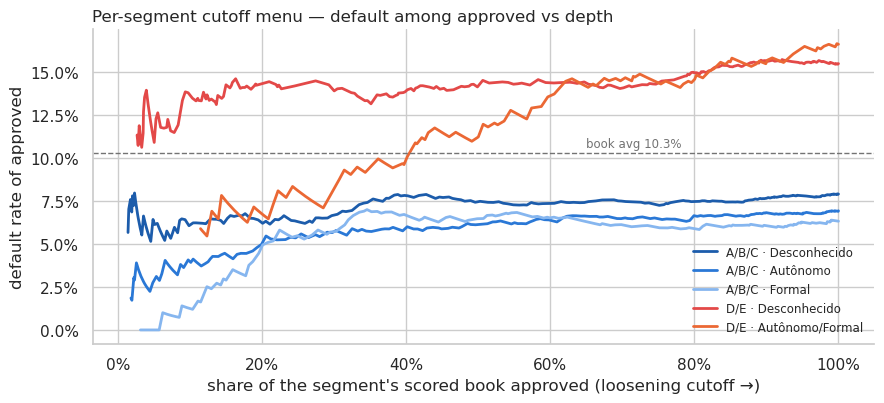

In [2]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for s in NAMED:
    m = menus[s][menus[s]["n"] >= 50]                 # unstable head (n < 50) masked
    ax.plot(m["n"] / m["n"].iloc[-1], m["rate"], color=C_SEG[s], lw=2, label=s)
ax.axhline(lab["OVER30M2"].mean(), color="0.45", ls="--", lw=1)
ax.text(0.65, lab["OVER30M2"].mean() + 0.003, f"book avg {lab['OVER30M2'].mean():.1%}",
        color="0.45", fontsize=8.5)
ax.set_xlabel("share of the segment's scored book approved (loosening cutoff →)")
ax.set_ylabel("default rate of approved")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Per-segment cutoff menu — default among approved vs depth", loc="left")
ax.legend(fontsize=8.5, frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

## 2. The policy frontier — sweep the risk tolerance τ

Each τ induces one full policy (a cutoff per segment + block decisions); the curve shows the
whole family on the book: share kept × default of the kept.

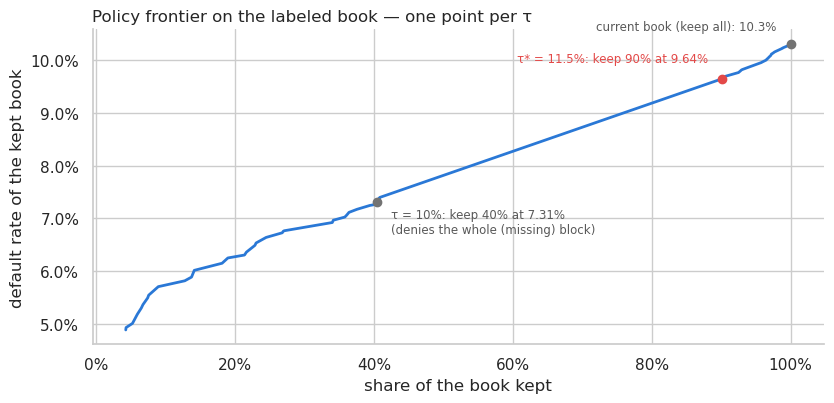

In [3]:
def policy_at(tau):
    """τ → (kept_n, kept_bads, {segment: score_min or inf}, {block: bool})."""
    kept_n = kept_b = 0
    cuts, keeps = {}, {}
    for s in NAMED:
        ok = menus[s][menus[s]["rate"] <= tau]
        cuts[s] = ok["score"].iloc[-1] if len(ok) else np.inf
        if len(ok):
            kept_n += int(ok["n"].iloc[-1]); kept_b += int(ok["bads"].iloc[-1])
    for k, (n, b) in blocks.items():
        keeps[k] = b / n <= tau
        if keeps[k]:
            kept_n += n; kept_b += b
    return kept_n, kept_b, cuts, keeps

taus = np.arange(0.05, 0.1701, 0.001)
front = pd.DataFrame([(t, *policy_at(t)[:2]) for t in taus], columns=["tau", "n", "bads"])
front["kept"] = front["n"] / len(lab)
front["default"] = front["bads"] / front["n"]

TAU_STAR = 0.115
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(front["kept"], front["default"], color="#2a78d6", lw=2)
ax.scatter([1.0], [lab["OVER30M2"].mean()], color="0.45", zorder=3)
ax.annotate("current book (keep all): 10.3%", (1.0, lab["OVER30M2"].mean()),
            xytext=(-10, 10), textcoords="offset points", ha="right", fontsize=8.5, color="0.35")
n_, b_, _, _ = policy_at(TAU_STAR)
ax.scatter([n_ / len(lab)], [b_ / n_], color="#e34948", zorder=3)
ax.annotate(f"τ* = 11.5%: keep {n_/len(lab):.0%} at {b_/n_:.2%}", (n_ / len(lab), b_ / n_),
            xytext=(-10, 12), textcoords="offset points", ha="right", fontsize=8.5, color="#e34948")
n_, b_, _, _ = policy_at(0.10)
ax.scatter([n_ / len(lab)], [b_ / n_], color="0.45", zorder=3)
ax.annotate(f"τ = 10%: keep {n_/len(lab):.0%} at {b_/n_:.2%}\n(denies the whole (missing) block)",
            (n_ / len(lab), b_ / n_), xytext=(10, -22), textcoords="offset points",
            fontsize=8.5, color="0.35")
ax.set_xlabel("share of the book kept")
ax.set_ylabel("default rate of the kept book")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Policy frontier on the labeled book — one point per τ", loc="left")
sns.despine()
plt.tight_layout()
plt.show()

**Key takeaway**: the frontier has a **cliff at τ = 11.5%** — the `(missing)` block (49% of the
book, 11.5% default) enters or leaves whole. Below it (τ = 10%) the policy keeps only 40% of the
book at 7.3%: commercially unviable today, but it prices the **data-acquisition lever** — every
applicant converted from `(missing)` into a named cell moves the book toward that curve. Above
the cliff, τ* = 11.5% keeps 90% at 9.64%.

## 3. Operating point → `references/policy_v1.yaml`

τ* = 11.5% (conservative: prunes only units measurably worse than the `(missing)` block, the
book's pivot). The resulting rules — note the appetite lever emerging from data: **no score gate
in A/B/C, real cutoffs in D/E, scoreless D/E denied**.

In [4]:
_, _, cuts, keeps = policy_at(TAU_STAR)
policy = {
    "tau": TAU_STAR,
    "segments": {s: {"score_min": None if cuts[s] == menus[s]["score"].min() else float(cuts[s]),
                     "scoreless": "approve" if keeps.get(f"{s} [sem score]") else "deny"}
                 for s in NAMED}
    | {"(missing)": {"score_min": None, "scoreless": "approve" if keeps["(missing)"] else "deny"}},
}
pol.save_policy(policy, PROJECT_DIR / "references" / "policy_v1.yaml")

kept = pol.approve(lab, policy)
print(f"book: kept {kept.mean():.1%} at {lab.loc[kept, 'OVER30M2'].mean():.2%} "
      f"(removed {1 - kept.mean():.1%}, defaulting at {lab.loc[~kept, 'OVER30M2'].mean():.2%})")
pd.DataFrame(policy["segments"]).T

book: kept 90.0% at 9.64% (removed 10.0%, defaulting at 16.33%)


,score_min,scoreless
A/B/C · Desconhecido,NaN,approve
A/B/C · Autônomo,NaN,approve
A/B/C · Formal,NaN,approve
D/E · Desconhecido,595.0,deny
D/E · Autônomo/Formal,518.0,deny
(missing),NaN,approve


## 4. Extrapolation scenario — ⚠ hypothesis, not measurement

Applying the same rules to the unlabeled stock **assumes the within-`Contratado` risk ordering
transfers through-the-door** (coverage is symmetric — 1.0 §3 — but `Reprovado` was denied for
reasons possibly outside these four variables). Expected rates below are book-measured unit
rates, not observations.

In [5]:
unit_rate = {}
for s in NAMED:
    d = lab[(lab["segmento"] == s) & lab["score_klavi_2"].notna()]
    sm = policy["segments"][s]["score_min"]
    unit_rate[(s, "scored")] = d.loc[d["score_klavi_2"] >= (sm or -np.inf), "OVER30M2"].mean()
    unit_rate[(s, "scoreless")] = lab.loc[(lab["segmento"] == s) & lab["score_klavi_2"].isna(),
                                          "OVER30M2"].mean()
unit_rate[("(missing)", "scoreless")] = lab.loc[lab["segmento"] == "(missing)", "OVER30M2"].mean()
unit_rate[("(missing)", "scored")] = unit_rate[("(missing)", "scoreless")]

rows = []
for st in ["Aprovado", "Reprovado"]:
    d = app[app["STATUS"] == st]
    adm = d[pol.approve(d, policy)]
    kind = np.where(adm["score_klavi_2"].notna(), "scored", "scoreless")
    exp = np.mean([unit_rate[(s, k)] for s, k in zip(adm["segmento"], kind)])
    rows.append({"stock": st, "n": len(d), "admitted": len(adm),
                 "admitted_pct": len(adm) / len(d), "expected_default_HYP": exp})
pd.DataFrame(rows).round({"admitted_pct": 3, "expected_default_HYP": 4})

,stock,n,admitted,admitted_pct,expected_default_HYP
0,Aprovado,77223,70099,0.908,0.0958
1,Reprovado,119247,100900,0.846,0.0974


**Key takeaway**: the rules would admit 90.8% of the `Aprovado` stock (70.1k — mostly a *demand*
play, they already passed the current policy) and 84.6% of `Reprovado` (100.9k at an *assumed*
~9.7%). Funnel approval would jump 45.9% → ≈87% — **do not read this as a forecast**: the
`Reprovado` number rests entirely on the transfer hypothesis. Recommendation: adopt the cutoffs
on the current intake (measured −0.7 pp), and expand into `Reprovado` only via a **staged,
monitored test** (small random slice, e.g. per-segment caps), which also generates the labels
reject inference lacks today.

## Key takeaways

- **Frontier built**: τ-family of per-segment cutoff policies; cliff at the `(missing)` block
  (49% of book) — its conversion into named cells is the biggest structural lever (τ = 10%
  branch: 40% kept at 7.3%).
- **Operating point (policy_v1.yaml)**: τ* = 11.5% — keep 90% of the book at **9.64% vs 10.30%**;
  the removed 10% defaults at 16.3%. A/B/C: no score gate; D/E: score ≥ 595 / ≥ 518, scoreless
  denied; `(missing)`: approved at baseline.
- **Expansion is a flagged scenario**: `Aprovado` re-activation is low-risk demand; `Reprovado`
  entry (84% admissible under the rules) must go through a staged test, not a policy flip.
- **Next (3.3)**: disparate-impact check of these rules by `regiao`.